In [8]:
from anomalouslib.models.model_handler import save_model, load_model, get_class_def_from_notebook
from anomalouslib.models.testing_utils import evaluate_continuous, predict_continuous
from anomalouslib.data.preprocessing import generate_classification_tensors
from anomalouslib.data.DatasetGenerator import DatasetGenerator
from anomalouslib.models.training_utils import train_model
from sklearn.preprocessing import LabelEncoder

from torch.utils.data import TensorDataset, DataLoader
import torch.nn.functional as F
import torch.nn as nn
import pandas as pd
import torch

In [9]:
dg = DatasetGenerator(num_particules=10000)

generators = [
    ("rw", dg.generate_RandomWalk),
    ("bm", dg.generate_BrownianMotion),
    ("ctrw", dg.generate_ContinuousTimeRandomWalk),
    ("fbm", dg.generate_FractionalBrownianMotion),
    ("lw", dg.generate_LevyWalks),
    ("attm", dg.generate_AnnealedTransitTimeModel),
    ("sbm", dg.generate_ScaledBrownianMotion),
]

dataframes = []
for prefix, func in generators:
    df = func(random_params=True, num_passos=200)
    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)
data

c:\Users\jmass\Documents\GitHub\TFG GEINF\AnomalousApp\venv\Lib\site-packages\fbm\fbm.py:171: UserWarning: Combination of increments n and Hurst value H invalid for Davies-Harte method. Reverting to Hosking method. Occurs when n is small and Hurst is close to 1. 
  warnings.warn(


1.5


,coords,num_steps,attributes
0,"[[0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, -1.0, -1....",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
1,"[[0.0, -1.0, -2.0, -2.0, -2.0, -2.0, -2.0, -2....",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
2,"[[0.0, -1.0, -1.0, -1.0, -1.0, -1.0, -2.0, -3....",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
3,"[[0.0, -1.0, -1.0, 0.0, -1.0, -1.0, -1.0, -2.0...",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
4,"[[0.0, -1.0, -2.0, -1.0, -1.0, 0.0, 0.0, -1.0,...",200,"{'trajectory_type': 'Random Walk', 'movement_t..."
...,...,...,...
69995,"[[1.0799966769401823, -2.1574262350468603, -0....",200,"{'trajectory_type': 'Scaled Brownian Motion', ..."
69996,"[[-0.7990879886492118, -0.192100265278761, -0....",200,"{'trajectory_type': 'Scaled Brownian Motion', ..."
69997,"[[-0.3620214504384155, 0.820738975941416, 0.29...",200,"{'trajectory_type': 'Scaled Brownian Motion', ..."
69998,"[[0.6142880668568583, 1.3439679331131464, 1.91...",200,"{'trajectory_type': 'Scaled Brownian Motion', ..."


In [11]:
le = LabelEncoder()
# Fit the LabelEncoder with the unique values of trajectory_type
le.fit(data["attributes"].apply(lambda x: x['trajectory_type']))
X_tensor, y_tensor = generate_classification_tensors(data, 'trajectory_type', le)

In [12]:
# Get X_train, X_val, X_test, y_train, y_val and y_test
n, train_end, val_end = len(X_tensor), int(0.7 * len(X_tensor)), int(0.85 * len(X_tensor))
X_train, X_val, X_test = X_tensor[:train_end], X_tensor[train_end:val_end], X_tensor[val_end:]
y_train, y_val, y_test = y_tensor[:train_end], y_tensor[train_end:val_end], y_tensor[val_end:]

In [13]:
# Set up the DataLoaders
learning_batch_size = 32
try_batch_size = 1

train_dataset = TensorDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=learning_batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=try_batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=try_batch_size, shuffle=True)

In [14]:
# 6. Define the CNN architecture
class TrajectoryTypeClassifier(nn.Module):
    def __init__(self, input_channels, num_classes):
        super().__init__()
        # Block 1: 32 channels
        self.bn1_1 = nn.BatchNorm1d(32)
        self.bn1_2 = nn.BatchNorm1d(32)
        self.bn1_3 = nn.BatchNorm1d(32)
        # Block 2: 64 channels
        self.bn2_1 = nn.BatchNorm1d(64)
        self.bn2_2 = nn.BatchNorm1d(64)
        self.bn2_3 = nn.BatchNorm1d(64)
        # Block 3: 128 channels
        self.bn3_1 = nn.BatchNorm1d(128)
        self.bn3_2 = nn.BatchNorm1d(128)
        self.bn3_3 = nn.BatchNorm1d(128)

        # First convolutional block
        self.first_conv = nn.Conv1d(input_channels, 32, kernel_size=3, padding=1)
        self.conv1_32 = nn.Conv1d(32, 32, kernel_size=3, padding=1)
        self.conv2_32 = nn.Conv1d(32, 32, kernel_size=3, padding=1)

        # Second convolutional block
        self.conv_32_64 = nn.Conv1d(32, 64, kernel_size=3, padding=1)
        self.conv1_64 = nn.Conv1d(64, 64, kernel_size=3, padding=1)
        self.conv2_64 = nn.Conv1d(64, 64, kernel_size=3, padding=1)

        # Third convolutional block
        self.conv_64_128 = nn.Conv1d(64, 128, kernel_size=3, padding=1)
        self.conv1_128 = nn.Conv1d(128, 128, kernel_size=3, padding=1)
        self.conv2_128 = nn.Conv1d(128, 128, kernel_size=3, padding=1)

        # Pooling and fully connected layers
        self.max_pool = nn.MaxPool1d(2)
        self.avg_pool = nn.AdaptiveAvgPool1d(4)
        self.fc1 = nn.Linear(128 * 4, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, num_classes)

    
    def forward(self, data):
        a_resnet = self.first_conv(data)
        a_resnet = self.bn1_1(a_resnet)
        a_resnet = F.relu(a_resnet)

        a = self.conv1_32(a_resnet)
        a = self.bn1_2(a)
        a = F.relu(a)

        a = self.conv2_32(a)
        a = self.bn1_3(a)
        a = F.relu(a)

        a = a + a_resnet
        a = self.max_pool(a)

        b_resnet = self.conv_32_64(a)
        b_resnet = self.bn2_1(b_resnet)
        b_resnet = F.relu(b_resnet)

        b = self.conv1_64(b_resnet)
        b = self.bn2_2(b)
        b = F.relu(b)

        b = self.conv2_64(b)
        b = self.bn2_3(b)
        b = F.relu(b)

        b = b + b_resnet
        b = self.max_pool(b)

        c_resnet = self.conv_64_128(b)
        c_resnet = self.bn3_1(c_resnet)
        c_resnet = F.relu(c_resnet)

        c = self.conv1_128(c_resnet)
        c = self.bn3_2(c)
        c = F.relu(c)

        c = self.conv2_128(c)
        c = self.bn3_3(c)
        c = F.relu(c)

        c = c + c_resnet
        c = self.avg_pool(c)
        c = c.view(c.size(0), -1)  # Flatten the output
        
        c = F.relu(self.fc1(c))
        c = F.relu(self.fc2(c))
        c = self.fc3(c)
        # c = F.softmax(c, dim=1) # New
        return c

In [16]:
import json

with open("trainingTrajectoryTypeClassifier.ipynb", "r", encoding="utf-8") as f:
    nb = json.load(f)
model_source = nb["cells"][6]["source"]
if isinstance(model_source, list):
    model_source = "".join(model_source)

print(model_source)

# 6. Define the CNN architecture
class TrajectoryTypeClassifier(nn.Module):
    def __init__(self, input_channels, num_classes):
        super().__init__()
        # Block 1: 32 channels
        self.bn1_1 = nn.BatchNorm1d(32)
        self.bn1_2 = nn.BatchNorm1d(32)
        self.bn1_3 = nn.BatchNorm1d(32)
        # Block 2: 64 channels
        self.bn2_1 = nn.BatchNorm1d(64)
        self.bn2_2 = nn.BatchNorm1d(64)
        self.bn2_3 = nn.BatchNorm1d(64)
        # Block 3: 128 channels
        self.bn3_1 = nn.BatchNorm1d(128)
        self.bn3_2 = nn.BatchNorm1d(128)
        self.bn3_3 = nn.BatchNorm1d(128)

        # First convolutional block
        self.first_conv = nn.Conv1d(input_channels, 32, kernel_size=3, padding=1)
        self.conv1_32 = nn.Conv1d(32, 32, kernel_size=3, padding=1)
        self.conv2_32 = nn.Conv1d(32, 32, kernel_size=3, padding=1)

        # Second convolutional block
        self.conv_32_64 = nn.Conv1d(32, 64, kernel_size=3, padding=1)
        self.conv1_64 = 

In [17]:
input_channels = 2

# Initialize the model this way to easily save parameters later
model_params = {
    "input_channels": input_channels,
    "num_classes": len(le.classes_)
}

model = TrajectoryTypeClassifier(**model_params)

In [18]:
# optimizer=torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-3)
# scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
#     optimizer, 
#     mode='min',  # Minimize val_loss
#     factor=0.2,  # Reduce LR to 20% of current
#     patience=3,  # Wait 3 epochs without improvement
#     verbose=True  # Show messages
# )


# best_model = train_model(
#     model=model,
#     criterion=nn.CrossEntropyLoss(),
#     optimizer=optimizer,
#     num_epochs=15,
#     train_loader=train_loader,
#     val_loader=val_loader,
#     scheduler=scheduler,
#     print_epoch=True,
#     patience=5
# )

# 8. Configure training
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 9. Train the model
num_epochs = 15

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    
    for inputs, labels in train_loader:
        optimizer.zero_grad()
        outputs = model(inputs)
        # print(outputs, labels)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")

Epoch [1/15], Loss: 0.8847
Epoch [2/15], Loss: 0.4402
Epoch [2/15], Loss: 0.4402
Epoch [3/15], Loss: 0.3259
Epoch [3/15], Loss: 0.3259
Epoch [4/15], Loss: 0.2857
Epoch [4/15], Loss: 0.2857
Epoch [5/15], Loss: 0.2528
Epoch [5/15], Loss: 0.2528
Epoch [6/15], Loss: 0.2334
Epoch [6/15], Loss: 0.2334
Epoch [7/15], Loss: 0.2145
Epoch [7/15], Loss: 0.2145
Epoch [8/15], Loss: 0.2077
Epoch [8/15], Loss: 0.2077
Epoch [9/15], Loss: 0.1946
Epoch [9/15], Loss: 0.1946
Epoch [10/15], Loss: 0.1944
Epoch [10/15], Loss: 0.1944
Epoch [11/15], Loss: 0.1777
Epoch [11/15], Loss: 0.1777
Epoch [12/15], Loss: 0.1770
Epoch [12/15], Loss: 0.1770
Epoch [13/15], Loss: 0.1629
Epoch [13/15], Loss: 0.1629
Epoch [14/15], Loss: 0.1672
Epoch [14/15], Loss: 0.1672
Epoch [15/15], Loss: 0.1545
Epoch [15/15], Loss: 0.1545


In [19]:
with torch.no_grad():
    test_outputs = model(X_test)
    _, predicted = torch.max(test_outputs, 1)  # Índices de las clases predichas
    true_labels = torch.argmax(y_test, dim=1)  # Convertir one-hot a índices
    accuracy = (predicted == true_labels).float().mean()
    print(f'Test Accuracy: {accuracy.item():.4f}')

Test Accuracy: 0.5617


In [20]:
import random

# Select the first example from X_test and add a batch dimension
random_value = random.randint(1, 500)
# print("Random value between 1 and 500:", random_value)
first_example = X_test[random_value].unsqueeze(0)  # shape: (1, 2, 200)

# Pass through the model
model.eval()
with torch.no_grad():
    output = model(first_example)
    predicted_class = torch.argmax(output, dim=1).item()

# Show the result
print("Prediction (class index):", predicted_class)
print("Predicted class:", le.inverse_transform([predicted_class])[0])
# Show the real class
true_class = torch.argmax(y_test[random_value]).item()
print("True class:", le.inverse_transform([true_class])[0])

Prediction (class index): 3
Predicted class: Fractional Brownian Motion
True class: Random Walk


In [22]:
evaluate_continuous(model, X_test, y_test)

Test MSE: 2345.9578


2345.957763671875

In [23]:
predict_continuous(model, X_test, y_test, num_samples=10)

Predicciones:


KeyError: 'Predicción'

In [24]:
SAVE_PATH = "../../models/"

In [25]:
import torch
import dill
import os
import inspect
import torch.nn as nn
import torch.nn.functional as F

def save_model(model_instance, model_source, attributes, input_channels, model_name=None, path=None, le=None):
    if model_name is None:
        model_name = model_instance.__class__.__name__
    filename = f"{model_name}.pth"
    if path is not None:
        os.makedirs(path, exist_ok=True)
        save_path = os.path.join(path, filename)
    else:
        save_path = filename
    torch.save({
        "model_name": model_name,
        "model_type": "type_classifier",
        "model_source": model_source,
        "state_dict": model_instance.state_dict(),
        "attributes": attributes,
        "input_channels": input_channels
        , **({"le": le} if le is not None else {})
    }, save_path, pickle_module=dill)


save_model(model_instance=model,
           model_source=model_source,
           attributes=model_params,
           input_channels=input_channels,
           path=SAVE_PATH,
           le=le
           )

In [26]:
import torch
import dill
import os
import inspect
import torch.nn as nn
import torch.nn.functional as F

def load_model(model_path):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint = torch.load(model_path, map_location=device, pickle_module=dill)
    
    # Execute source code to recreate the class
    exec(checkpoint["model_source"], globals())  # The class is defined in global scope
    
    # Instantiate the model with its original arguments
    model_class = globals()[checkpoint["model_source"].split("class ")[1].split("(")[0].strip()]
    model = model_class(**checkpoint["attributes"])
    model.load_state_dict(checkpoint["state_dict"])
    model.to(device)
    model.eval()
    if checkpoint["le"] is not None:
        return model, checkpoint["le"]
    return model

model, le = load_model(
    SAVE_PATH + "TrajectoryTypeClassifier.pth"
)

In [27]:
import random

# Select the first example from X_test and add a batch dimension
random_value = random.randint(1, 500)
# print("Random value between 1 and 500:", random_value)
first_example = X_test[random_value].unsqueeze(0)  # shape: (1, 2, 200)

# Pass through the model
model.eval()
with torch.no_grad():
    output = model(first_example)
    predicted_class = torch.argmax(output, dim=1).item()

# Show the result
print("Prediction (class index):", predicted_class)
print("Predicted class:", le.inverse_transform([predicted_class])[0])
# Show the real class
true_class = torch.argmax(y_test[random_value]).item()
print("True class:", le.inverse_transform([true_class])[0])

Prediction (class index): 4
Predicted class: Lévy Walk
True class: Lévy Walk


1.5
torch.Size([1, 2, 400]) torch.Size([1, 7])
tensor([[-8.5288,  1.0143, -7.0782,  5.1222, -0.1238, -8.0242, -6.9565]])
Fractional Brownian Motion


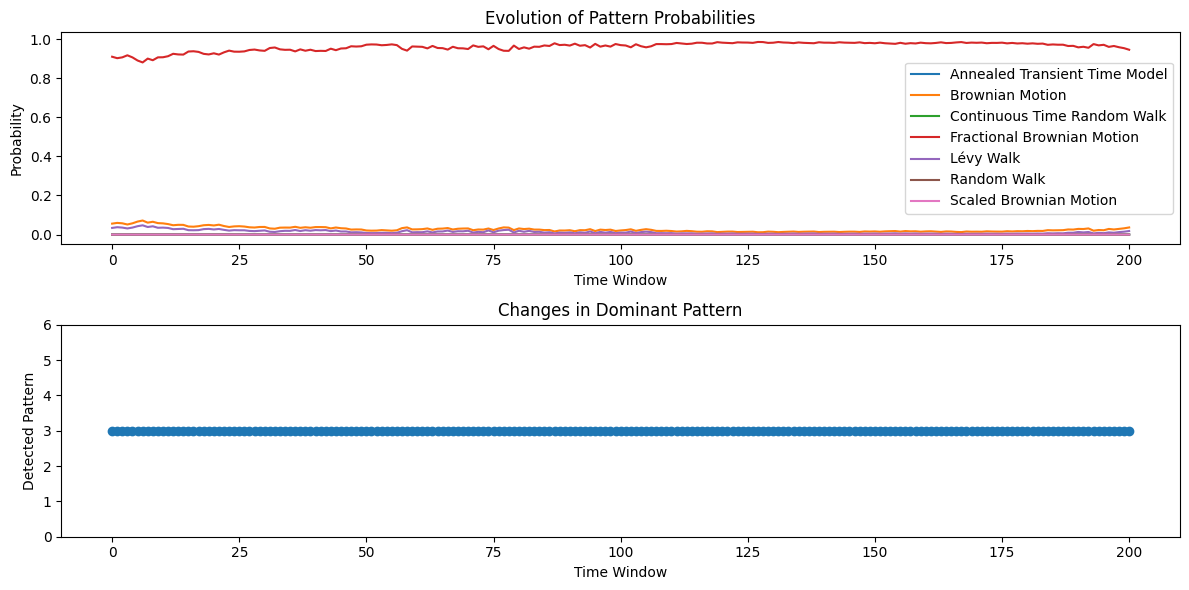

In [29]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

traj = DatasetGenerator(num_particules=1).generate_AnnealedTransitTimeModel(num_passos=400, random_params=True)
X_tensor, y_tensor = generate_classification_tensors(traj, 'trajectory_type', le)
print(X_tensor.shape, y_tensor.shape)
with torch.no_grad():
    out = model(X_tensor)
    print(out)
    predicted_class = torch.argmax(out, dim=1).item()
    print(le.inverse_transform([predicted_class])[0])

# Use unfold on dimension 2 (length dimension n)
X_unfolded = X_tensor.unfold(dimension=2, size=200, step=1)  # [1, 2, 91, 200]

# Reorder so each window is an independent tensor
X_windows = X_unfolded.permute(2, 0, 1, 3)  # [91, 1, 2, 10]

# Convert to a list of tensors of shape [1, 2, 10]
X_list = [x for x in X_windows]  # list of 91 tensors

X_adjusted = []

for window in X_list:
    # Extract the starting point [1, 2, 1] → expand for broadcasting
    start = window[:, :, 0].unsqueeze(-1)
    # Subtract the initial point from the entire window
    adjusted = window - start
    X_adjusted.append(adjusted)

model.eval()
outputs = []
values = []
with torch.no_grad():
    for x in X_adjusted:
        out = model(x)
        out = F.softmax(out, dim=1)
        predicted_class = torch.argmax(out, dim=1).item()
        array = out.numpy()[0]
        outputs.append(np.array(array))
        values.append(le.inverse_transform([predicted_class])[0])

outputs = np.array(outputs)
if outputs.size > 0:
    plt.figure(figsize=(12, 6))
    
    # Probability plot
    plt.subplot(2, 1, 1)
    for i in range(7):
        plt.plot(outputs[:, i], label=f'{le.inverse_transform([i])[0]}')
    plt.title('Evolution of Pattern Probabilities')
    plt.xlabel('Time Window')
    plt.ylabel('Probability')
    plt.legend()
    
    # Dominant pattern plot
    plt.subplot(2, 1, 2)
    dominant_pattern = np.argmax(outputs, axis=1)
    plt.plot(dominant_pattern, 'o-')
    plt.title('Changes in Dominant Pattern')
    plt.xlabel('Time Window')
    plt.ylabel('Detected Pattern')
    plt.yticks(range(7))
    
    plt.tight_layout()
    plt.show()

In [30]:
from collections import Counter
import numpy as np

# Get the index of the dominant class for each window
dominant_pattern = np.argmax(outputs, axis=1)
# Convert indices to class names using the label encoder
labels = le.inverse_transform(dominant_pattern)
print("dominant_pattern:", dominant_pattern)
print(Counter(labels).most_common(7))
# Print the legend of class indices
for i in range(len(le.classes_)):
    print(f"{i}: {le.inverse_transform([i])[0]}")

dominant_pattern: [3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3
 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3]
[('Fractional Brownian Motion', 201)]
0: Annealed Transient Time Model
1: Brownian Motion
2: Continuous Time Random Walk
3: Fractional Brownian Motion
4: Lévy Walk
5: Random Walk
6: Scaled Brownian Motion


In [32]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Generate two trajectories of different types and concatenate them
dg = DatasetGenerator(num_particules=1)
traj1 = dg.generate_FractionalBrownianMotion(num_passos=300, random_params=True)
traj2 = dg.generate_ContinuousTimeRandomWalk(num_passos=300, random_params=True)
traj3 = dg.generate_LevyWalks(num_passos=300, random_params=True)

# Concatenate the trajectories
traj_concat = traj1.copy()
# Get the last value of traj1
last_coords_traj1 = np.array(traj1.iloc[0]["coords"])
last_point = last_coords_traj1[:, -1]

# Get the values of traj2 and add the last point of traj1
coords_traj2 = np.array(traj2.iloc[0]["coords"])
coords_traj2_shifted = coords_traj2 + last_point[:, None]

# Concatenate the coordinates
coords_concat = np.concatenate([last_coords_traj1, coords_traj2_shifted], axis=1)

# Get the last value of traj1
last_point2 = coords_concat[:, -1]

# Get the values of traj3 and add the last point of traj2
coords_traj3 = np.array(traj3.iloc[0]["coords"])
coords_traj3_shifted = coords_traj3 + last_point2[:, None]

# Concatenate the coordinates
coords_concat = np.concatenate([coords_concat, coords_traj3_shifted], axis=1)

# Update the concatenated DataFrame
traj_concat.at[0, "coords"] = coords_concat.tolist()
traj_concat.at[0, "num_steps"] = coords_concat.shape[1]
traj_concat.at[0, "trajectory_type"] = traj1.iloc[0]["attributes"]["trajectory_type"] + "+" + traj2.iloc[0]["attributes"]["trajectory_type"]

traj = traj_concat

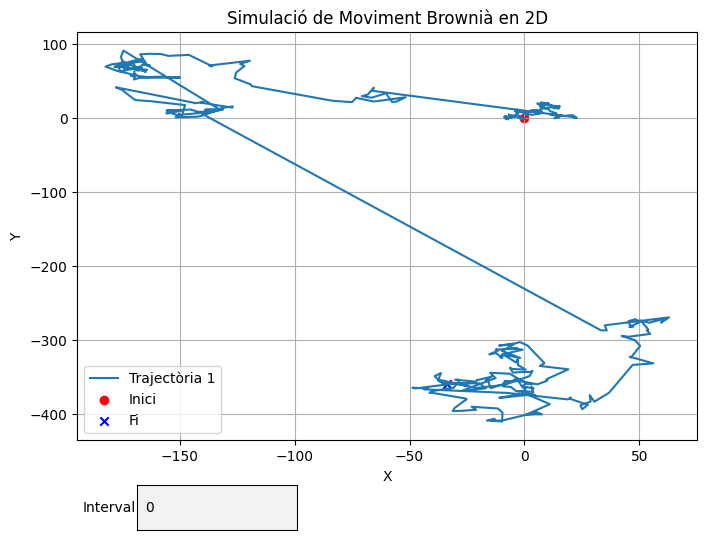

In [33]:
from anomalouslib.analysis.DataAnalyzer import DataAnalyzer
DataAnalyzer = DataAnalyzer(traj)
DataAnalyzer.mostrar_trajectories()

torch.Size([1, 2, 900]) torch.Size([1, 7])
tensor([[ -7.2443,  -3.5322,   0.2707,  -5.4639,   2.9086, -13.0198, -17.4960]])
Lévy Walk


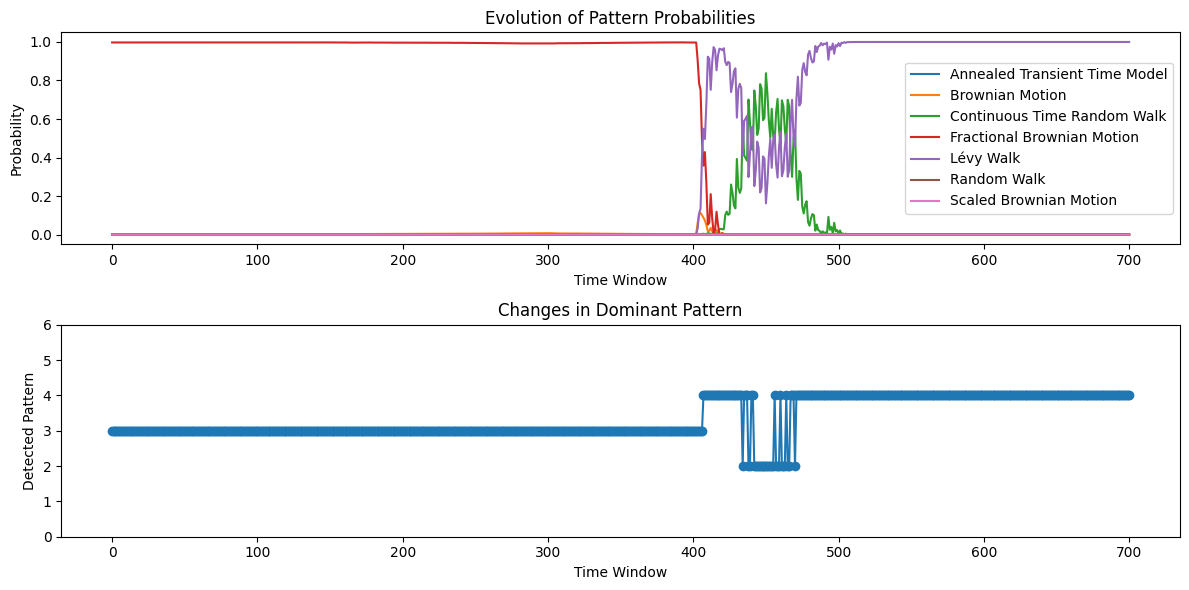

In [34]:
X_tensor, y_tensor = generate_classification_tensors(traj, 'trajectory_type', le)
print(X_tensor.shape, y_tensor.shape)
with torch.no_grad():
    out = model(X_tensor)
    print(out)
    predicted_class = torch.argmax(out, dim=1).item()
    print(le.inverse_transform([predicted_class])[0])

# Use unfold on dimension 2 (length dimension n)
X_unfolded = X_tensor.unfold(dimension=2, size=200, step=1)  # [1, 2, 91, 200]

# Reorder so each window is an independent tensor
X_windows = X_unfolded.permute(2, 0, 1, 3)  # [91, 1, 2, 10]

# Convert to a list of tensors of shape [1, 2, 10]
X_list = [x for x in X_windows]  # list of 91 tensors

X_adjusted = []

for window in X_list:
    # Extract the starting point [1, 2, 1] → expand for broadcasting
    start = window[:, :, 0].unsqueeze(-1)
    # Subtract the initial point from the entire window
    adjusted = window - start
    X_adjusted.append(adjusted)

model.eval()
outputs = []
values = []
with torch.no_grad():
    for x in X_adjusted:
        out = model(x)
        out = F.softmax(out, dim=1)
        predicted_class = torch.argmax(out, dim=1).item()
        array = out.numpy()[0]
        outputs.append(np.array(array))
        values.append(le.inverse_transform([predicted_class])[0])

outputs = np.array(outputs)
if outputs.size > 0:
    plt.figure(figsize=(12, 6))
    
    # Probability plot
    plt.subplot(2, 1, 1)
    for i in range(7):
        plt.plot(outputs[:, i], label=f'{le.inverse_transform([i])[0]}')
    plt.title('Evolution of Pattern Probabilities')
    plt.xlabel('Time Window')
    plt.ylabel('Probability')
    plt.legend()
    
    # Dominant pattern plot
    plt.subplot(2, 1, 2)
    dominant_pattern = np.argmax(outputs, axis=1)
    plt.plot(dominant_pattern, 'o-')
    plt.title('Changes in Dominant Pattern')
    plt.xlabel('Time Window')
    plt.ylabel('Detected Pattern')
    plt.yticks(range(7))
    
    plt.tight_layout()
    plt.show()

In [35]:
with torch.no_grad():
    test_outputs = model(X_tensor)
    _, predicted = torch.max(test_outputs, 1)  # Índices de las clases predichas
    true_labels = torch.argmax(y_tensor, dim=1)  # Convertir one-hot a índices
    accuracy = (predicted == true_labels).float().mean()
    print(f'Test Accuracy: {accuracy.item():.4f}')

Test Accuracy: 0.0000


In [36]:
X_test.shape, y_test.shape

(torch.Size([10500, 2, 200]), torch.Size([10500, 7]))

In [ ]:
X_tensor.shape, y_tensor.shape

(torch.Size([1, 2, 900]), torch.Size([1, 7]))

: 